# Exercise 11: Integration
### 03 November 2026

#### Instructions:
- make a function that performs Monte Carlo, Trapezoidal, and Simpson's Rule integration that outputs:
    - total area bounded by curve, x-axis, and x bounds
    - signed area (integral).
- function should accomodate to any continuous function.

#### Report figures:
- XL(?) plots = G figs

#### Report discussion:
- explain the figures. comment on why they work/when is one method more useful.

### Code

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy as sc

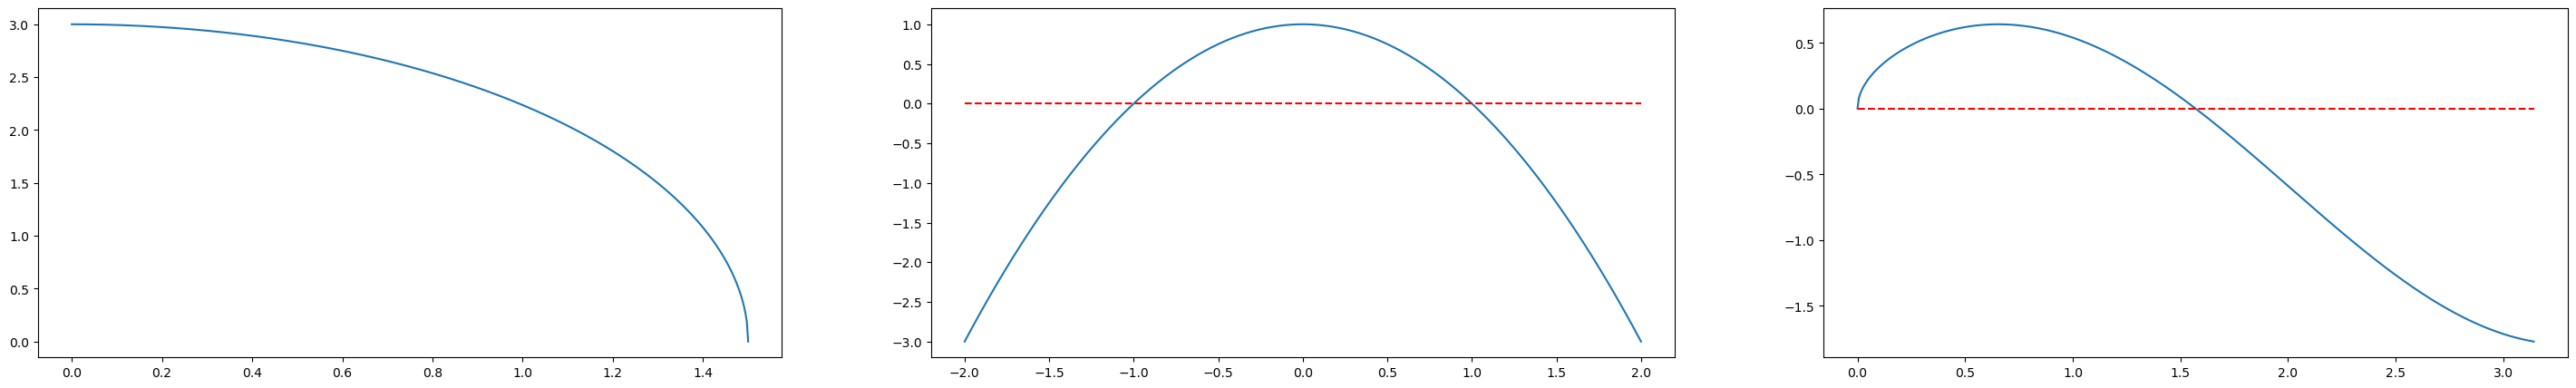

In [2]:
def dom(start, end, res=500):
    return np.linspace(start, end, res)

def test_1(x):
    return np.sqrt(9 - 4 * x**2)

def test_2(x):
    return -(x**2) + 1

def test_3(x):
    return np.cos(x)*np.sqrt(x)

x_1, x_2, x_3 = dom(0, 3/2), dom(-2, 2), dom(0, np.pi)

fig, ax = plt.subplots(1, 3, figsize=(36,5))
ax[0].plot(x_1, test_1(x_1))
ax[1].plot(x_2, test_2(x_2))
ax[1].plot(x_2, x_2 - x_2, 'r--')
ax[2].plot(x_3, test_3(x_3))
ax[2].plot(x_3, x_3 - x_3, 'r--')

In [14]:
def monte_carlo(f, a, b, tot=False, N=500):
    x_rand = np.random.uniform(a, b, N)
    if tot == False:
        y = f(x_rand)
    else:
        y = np.abs(f(x_rand))
    estimate = (b - a)*np.mean(y)
    return estimate, x_rand

def trapezoidal(f, a, b, tot=False, N=50):
    x = dom(a, b, N+1)
    h = (b - a) / N
    if tot == False:
        y=f(x)
    else:
        y = np.abs(f(x))
    y_right = y[1:]
    y_left = y[:-1]
    estimate = (h / 2) * np.sum(y_right + y_left)
    return estimate

def simp_13(f, a, b, tot=False, N=100):
    x = dom(a, b, N+1)
    h = (b - a) / (N+1)
    cs = 2*np.ones(N+1)
    cs[1::2] = 4; cs[0] = 1; cs[-1] = 1
    if tot == False:
        y = f(x)
    else:
        y = np.abs(f(x))
    contribs = cs*y
    estimate = (h / 3)*np.sum(contribs)
    return estimate

def simp_38(f, a, b, tot=False, N=100):
    x = dom(a, b, N+1)
    h = (b - a) / (N+1)
    cs = 3*np.ones(N+1)
    cs[3::3] = 2; cs[0] = 1; cs[-1] = 1
    if tot == False:
        y = f(x)
    else:
        y = np.abs(f(x))
    contribs = cs*y
    estimate = ((3*h)/8)*np.sum(contribs)
    return estimate
    
def print_calculations(fn, a, b):
    print('For function:', fn.__name__)
    print('    True value of signed area:', sc.integrate.quad(fn, a , b)[0])
    print("    Signed area:")
    print('        Monte Carlo:', monte_carlo(fn, a, b, 0, 1000000)[0])
    print('        Trapezoidal:', trapezoidal(fn, a, b, 0, 50))
    print("        Simpson's 1/3:", simp_13(fn, a, b))
    print("        Simpson's 3/8:", simp_38(fn, a, b))
    print('    Total bounded area:')
    print('        Monte Carlo:', monte_carlo(fn, a, b, 1, 1000000)[0])
    print('        Trapezoidal:', trapezoidal(fn, a, b, 1, 50))
    print("        Simpson's 1/3:", simp_13(fn, a, b, 1))
    print("        Simpson's 3/8:", simp_38(fn, a, b, 1))
    return

print_calculations(test_1, 0, 3/2)
print_calculations(test_2, -2, 2)
print_calculations(test_3, 0, np.pi)

For function: test_1
    True value of signed area: 3.534291735288518
    Signed area:
        Monte Carlo: 3.534819714392679
        Trapezoidal: 3.530552074985812
        Simpson's 1/3: 3.4987869861451792
        Simpson's 3/8: 3.4974471290055305
    Total bounded area:
        Monte Carlo: 3.5329279356641186
        Trapezoidal: 3.530552074985812
        Simpson's 1/3: 3.4987869861451792
        Simpson's 3/8: 3.4974471290055305
For function: test_2
    True value of signed area: -1.3333333333333335
    Signed area:
        Monte Carlo: -1.3411726564224005
        Trapezoidal: -1.3376000000000001
        Simpson's 1/3: -1.3201320132013203
        Simpson's 3/8: -1.291223762376238
    Total bounded area:
        Monte Carlo: 4.002272812377845
        Trapezoidal: 4.0064
        Simpson's 1/3: 3.9582838283828385
        Simpson's 3/8: 3.9307009900990093
For function: test_3
    True value of signed area: -0.8948314694841447
    Signed area:
        Monte Carlo: -0.8946730943647522
   

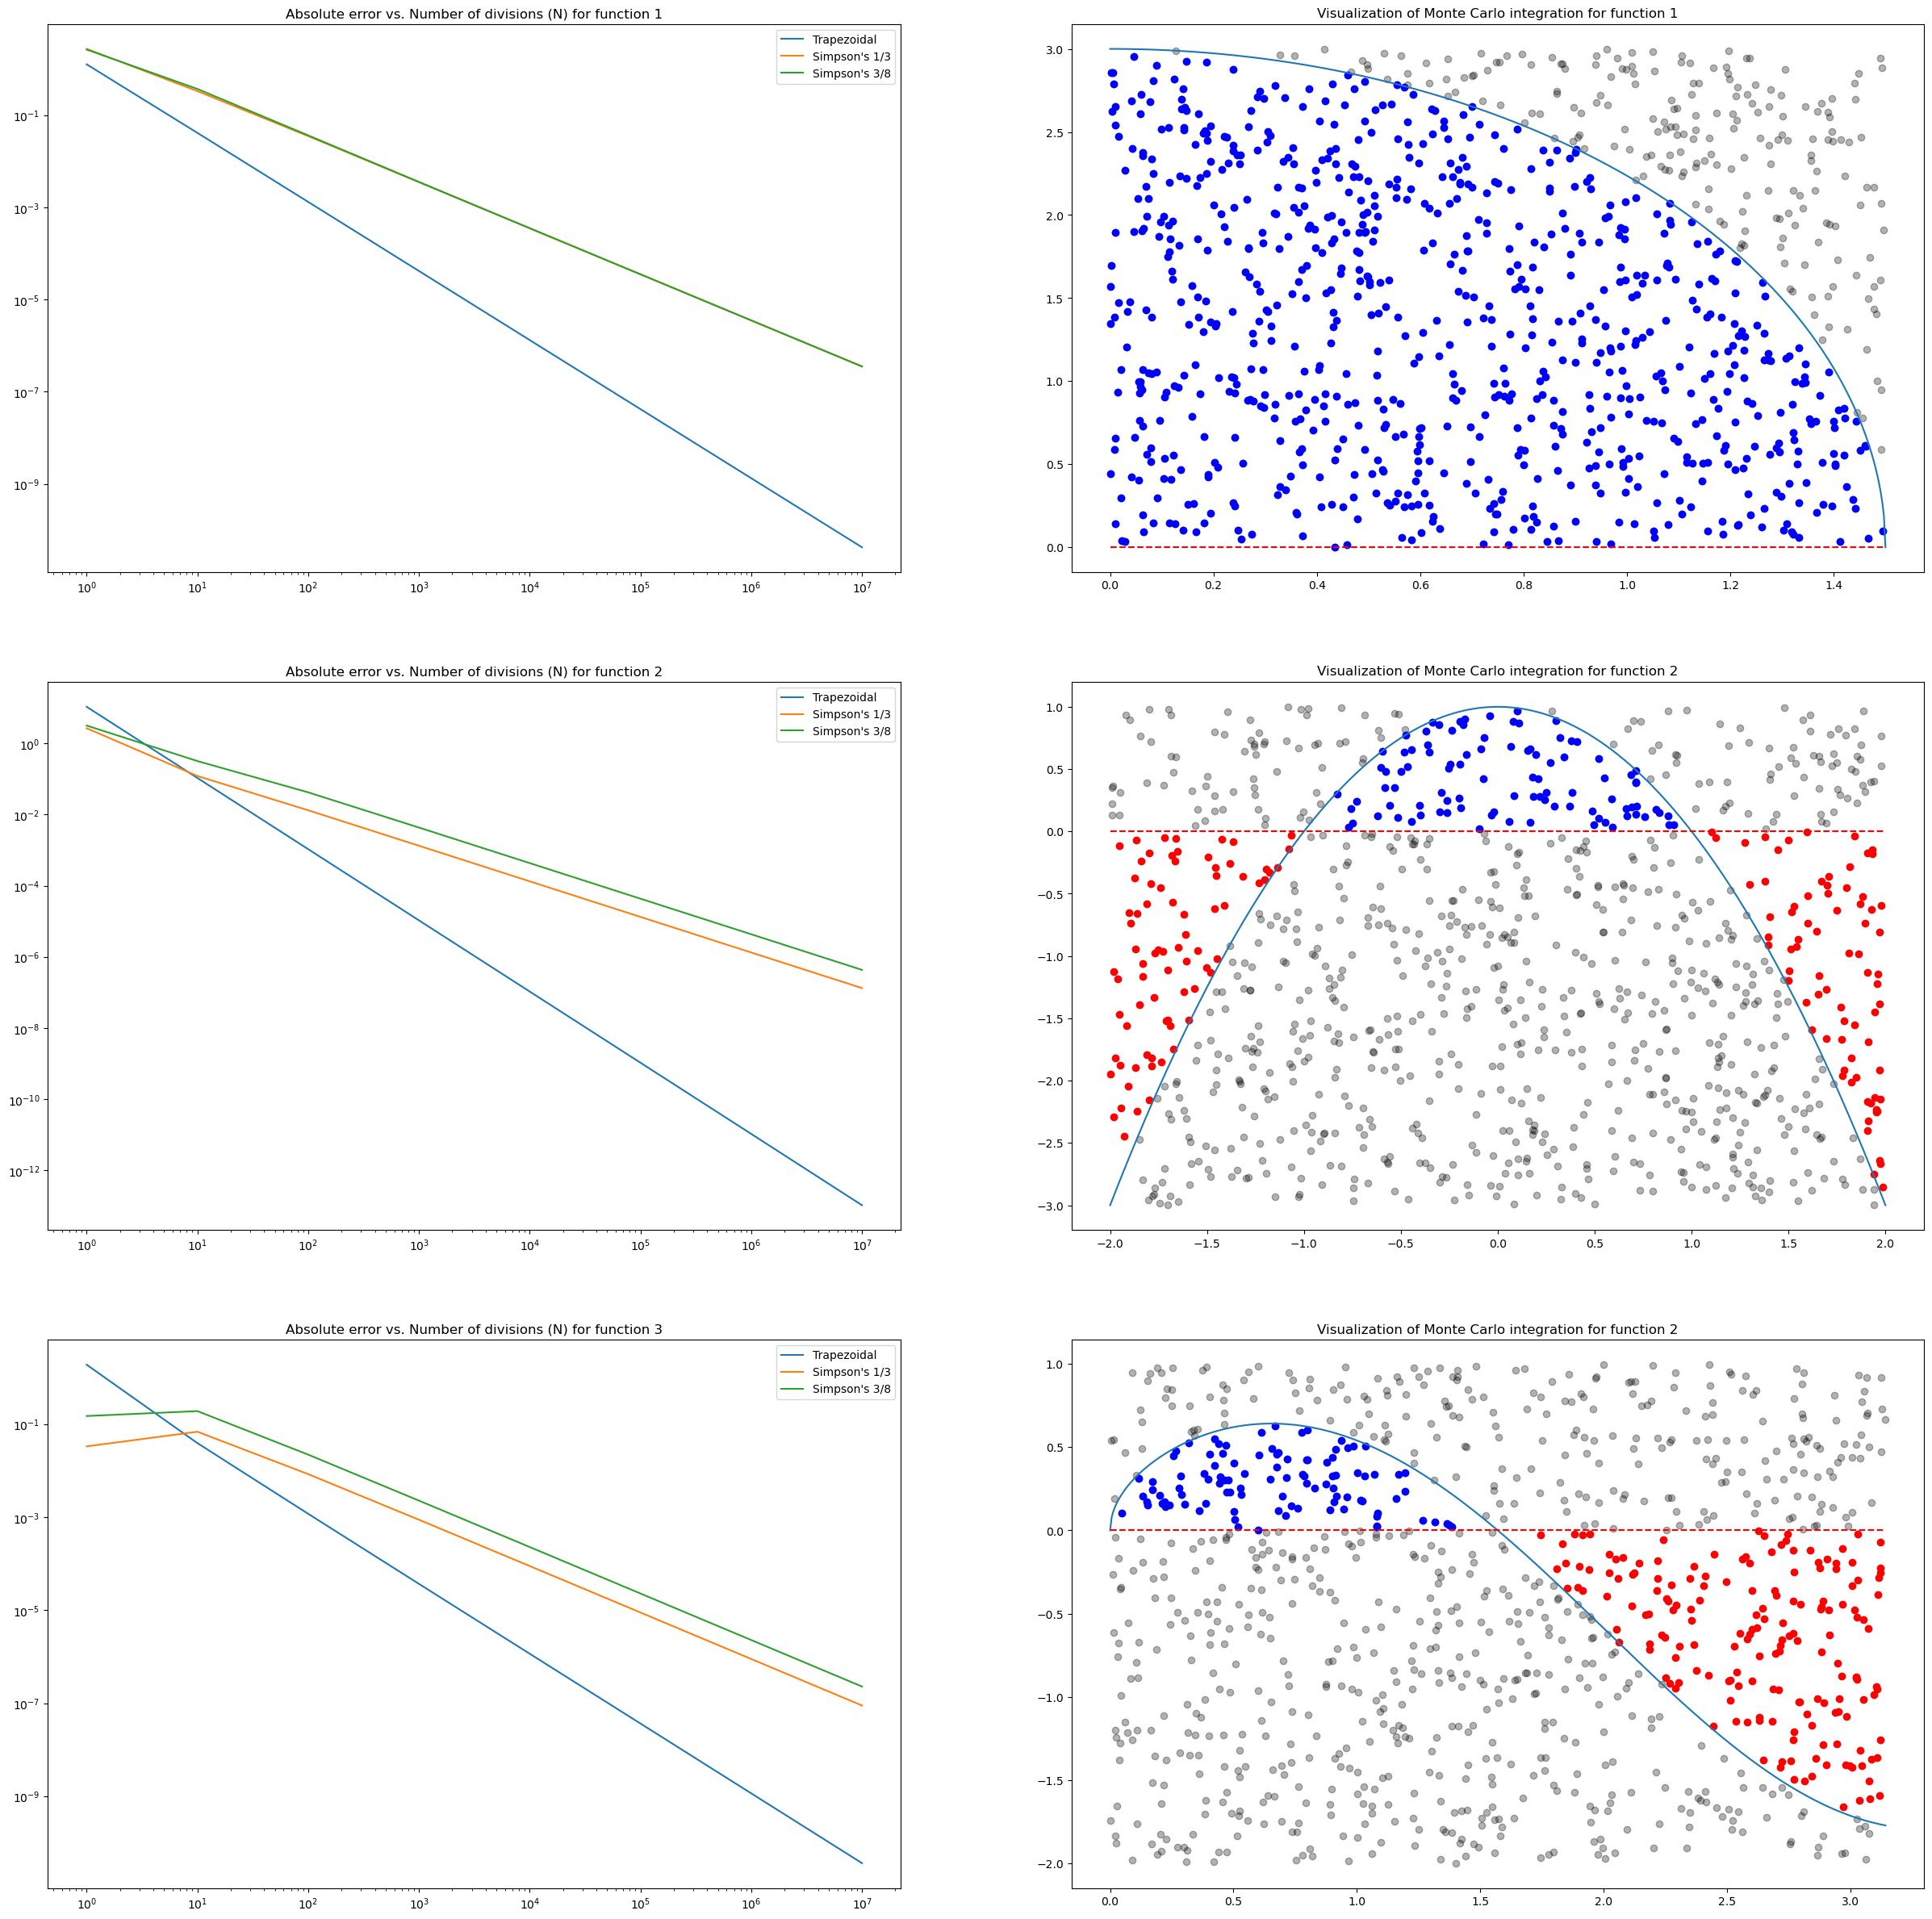

In [4]:
N = [1, 10, 100, 1000, 10000, 10000, 1000000, 1000000, 10000000]

def get_Error(f, a, b):
    true = sc.integrate.quad(f, a, b)[0]
    error_trap = []
    error_simp13 = []
    error_simp38 = []
    for n in N:
        tr = np.abs(true - trapezoidal(f, a, b, 0, n))
        simp13 = np.abs(true - simp_13(f, a, b, 0, n))
        simp38 = np.abs(true - simp_38(f, a, b, 0, n))
        error_trap.append(tr)
        error_simp13.append(simp13)
        error_simp38.append(simp38)
        
    return error_trap, error_simp13, error_simp38

def visualize_mc(f, a, b, y_min, y_max, N = 1000):
    x_rand = monte_carlo(f, a, b, 0, N)[1]
    y_rand = np.random.uniform(y_min, y_max, N)
    over_zero = (y_rand <= f(x_rand)) & (y_rand > 0)
    under_zero = (y_rand >= f(x_rand)) & (y_rand < 0)
                                         
    return x_rand, y_rand, over_zero, under_zero

err_1 = get_Error(test_1, 0, 3/2)
err_2 = get_Error(test_2, -2, 2)
err_3 = get_Error(test_3, 0, np.pi)

vmc_1x, vmc_1y, vmc_1over, vmc_1under  = visualize_mc(test_1, 0, 3/2, 0, 3)
vmc_2x, vmc_2y, vmc_2over, vmc_2under = visualize_mc(test_2, -2, 2, -3, 1)
vmc_3x, vmc_3y, vmc_3over, vmc_3under = visualize_mc(test_3, 0, np.pi, -2, 1)

y_min, y_max = -2, 1
x_rand = monte_carlo(test_2, 0, np.pi, 0, 1000)[1]
y_rand = np.random.uniform(y_min, y_max, 1000)

over_zero = (y_rand <= test_3(x_rand)) & (y_rand > 0)
under_zero = (y_rand >= test_3(x_rand)) & (y_rand < 0)



fig, ax = plt.subplots(3,2, figsize=(30, 30))
                                    
ax[0][0].set_xscale('log')
ax[0][0].set_yscale('log')
#ax[0][0].scatter(np.array(N), np.array(error_trap))
ax[0][0].plot(np.array(N), np.array(err_1[0]), label='Trapezoidal')
ax[0][0].plot(np.array(N), np.array(err_1[1]), label="Simpson's 1/3")
ax[0][0].plot(np.array(N), np.array(err_1[2]), label="Simpson's 3/8")
ax[0][0].legend()
ax[0][0].set_title("Absolute error vs. Number of divisions (N) for function 1")
ax[0][1].scatter(vmc_1x[~vmc_1under], vmc_1y[~vmc_1under], color='black', alpha=0.3)
ax[0][1].scatter(vmc_1x[vmc_1over], vmc_1y[vmc_1over], color='blue')
ax[0][1].scatter(vmc_1x[vmc_1under], vmc_1y[vmc_1under], color='red')
ax[0][1].plot(x_1, test_1(x_1))
ax[0][1].plot(x_1, x_1 - x_1, 'r--')
ax[0][1].set_title("Visualization of Monte Carlo integration for function 1")

ax[1][0].set_xscale('log')
ax[1][0].set_yscale('log')
#ax[0][0].scatter(np.array(N), np.array(error_trap))
ax[1][0].plot(np.array(N), np.array(err_2[0]), label='Trapezoidal')
ax[1][0].plot(np.array(N), np.array(err_2[1]), label="Simpson's 1/3")
ax[1][0].plot(np.array(N), np.array(err_2[2]), label="Simpson's 3/8")
ax[1][0].legend()
ax[1][0].set_title("Absolute error vs. Number of divisions (N) for function 2")
ax[1][1].scatter(vmc_2x[~vmc_2under], vmc_2y[~vmc_2under], color='black', alpha=0.3)
ax[1][1].scatter(vmc_2x[vmc_2over], vmc_2y[vmc_2over], color='blue')
ax[1][1].scatter(vmc_2x[vmc_2under], vmc_2y[vmc_2under], color='red')
ax[1][1].plot(x_2, test_2(x_2))
ax[1][1].plot(x_2, x_2 - x_2, 'r--')
ax[1][1].set_title("Visualization of Monte Carlo integration for function 2")

ax[2][0].set_xscale('log')
ax[2][0].set_yscale('log')
#ax[0][0].scatter(np.array(N), np.array(error_trap))
ax[2][0].plot(np.array(N), np.array(err_3[0]), label='Trapezoidal')
ax[2][0].plot(np.array(N), np.array(err_3[1]), label="Simpson's 1/3")
ax[2][0].plot(np.array(N), np.array(err_3[2]), label="Simpson's 3/8")
ax[2][0].legend()
ax[2][0].set_title("Absolute error vs. Number of divisions (N) for function 3")
ax[2][1].scatter(vmc_3x[~vmc_3under], vmc_3y[~vmc_3under], color='black', alpha=0.3)
ax[2][1].scatter(vmc_3x[vmc_3over], vmc_3y[vmc_3over], color='blue')
ax[2][1].scatter(vmc_3x[vmc_3under], vmc_3y[vmc_3under], color='red')
ax[2][1].plot(x_3, test_3(x_3))
ax[2][1].plot(x_3, x_3 - x_3, 'r--')
ax[2][1].set_title("Visualization of Monte Carlo integration for function 2")
plt.savefig('/home/jovyan/Buhangin_AP155/AP155_TX1_1sAY2627/ahrystanB/Figures/integrationgraphs.png')